# Évaluation du détecteur d'anomalies — RESILIENCE-ALPHA

**Domaine IA — validation de la détection d'anomalies**

Ce notebook évalue le détecteur d'anomalies (IsolationForest + distance robuste) sur un **scénario réel** :
trafic normal, puis attaque intense (surcharge + requêtes en erreur) contre l'API de paiement, puis retour au calme.

On compare les scores produits par le détecteur à la **vérité terrain** (la fenêtre d'attaque réelle)
et on calcule Precision, Recall, F1, AUC-ROC, le délai de détection et la matrice de confusion.


In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
import matplotlib.pyplot as plt

ATTACK_START = 1792500720.7
ATTACK_END   = 1792500767.4
THRESHOLD = 0.55

df = pd.read_csv("capture_scores.csv")
df["attaque_reelle"] = ((df["t"] >= ATTACK_START) & (df["t"] <= ATTACK_END)).astype(int)
df.head()

,t,score,over,attaque_reelle
0,1.792501e+09,0.005,0,0
1,1.792501e+09,0.003,0,0
2,1.792501e+09,0.002,0,0
3,1.792501e+09,0.002,0,0
4,1.792501e+09,0.001,0,0


## Métriques de performance

In [2]:
y_true = df["attaque_reelle"].values
y_pred = df["over"].values
scores = df["score"].values

precision = precision_score(y_true, y_pred, zero_division=0)
recall    = recall_score(y_true, y_pred, zero_division=0)
f1        = f1_score(y_true, y_pred, zero_division=0)
auc       = roc_auc_score(y_true, scores)

print(f"Precision : {precision:.3f}")
print(f"Recall    : {recall:.3f}")
print(f"F1-score  : {f1:.3f}")
print(f"AUC-ROC   : {auc:.3f}")

Precision : 0.811
Recall    : 0.915
F1-score  : 0.860
AUC-ROC   : 0.922


### Interprétation des métriques

- **Precision = 0.811** : lorsque le détecteur déclenche une alerte, il a raison dans **81 %** des cas. Les fausses alertes restent limitées.
- **Recall = 0.915** : le détecteur identifie **91,5 %** des secondes réellement sous attaque. Il laisse passer très peu d'anomalies — c'est la qualité la plus importante pour un système de cyber-résilience, où manquer une attaque est plus grave qu'une fausse alerte.
- **F1-score = 0.860** : moyenne harmonique de la précision et du rappel ; une valeur élevée confirme un bon équilibre entre les deux.
- **AUC-ROC = 0.922** : indépendamment du seuil choisi, le modèle distingue correctement « normal » et « anormal » dans **92 %** des cas. Le score d'anomalie est donc une mesure fiable, pas seulement le verdict binaire.

## Matrice de confusion et délai de détection

In [3]:
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
print("Matrice de confusion :")
print(f"  Vrais negatifs (normal OK)     : {tn}")
print(f"  Faux positifs  (fausse alerte) : {fp}")
print(f"  Faux negatifs  (attaque ratee) : {fn}")
print(f"  Vrais positifs (attaque vue)   : {tp}")

sous_attaque = df[df["attaque_reelle"] == 1]
detectees = sous_attaque[sous_attaque["over"] == 1]
if len(detectees):
    delai = detectees["t"].iloc[0] - ATTACK_START
    print(f"\nDelai de detection : {delai:.0f} secondes")

Matrice de confusion :
  Vrais negatifs (normal OK)     : 93
  Faux positifs  (fausse alerte) : 10
  Faux negatifs  (attaque ratee) : 4
  Vrais positifs (attaque vue)   : 43

Delai de detection : 4 secondes


### Interprétation de la matrice de confusion et du délai

- **Vrais positifs (43)** : attaques correctement détectées — l'essentiel de la fenêtre d'attaque.
- **Faux négatifs (4)** : attaques manquées, concentrées sur les **premières secondes**. C'est le temps nécessaire pour que le score franchisse le seuil et que la persistance (3 points consécutifs) se confirme : c'est le **délai de détection**, incompressible par conception.
- **Faux positifs (10)** : fausses alertes situées **juste après la fin de l'attaque**, le temps que le score redescende sous le seuil (inertie de retour au calme).
- **Vrais négatifs (93)** : périodes normales correctement classées.
- **Délai de détection = 4 s** : le détecteur confirme l'attaque en 4 secondes. Pour une reprise automatique, cette réactivité est satisfaisante.

## Visualisation : score au cours du temps

Zone rouge = attaque réelle ; ligne pointillée = seuil de décision (0.55).

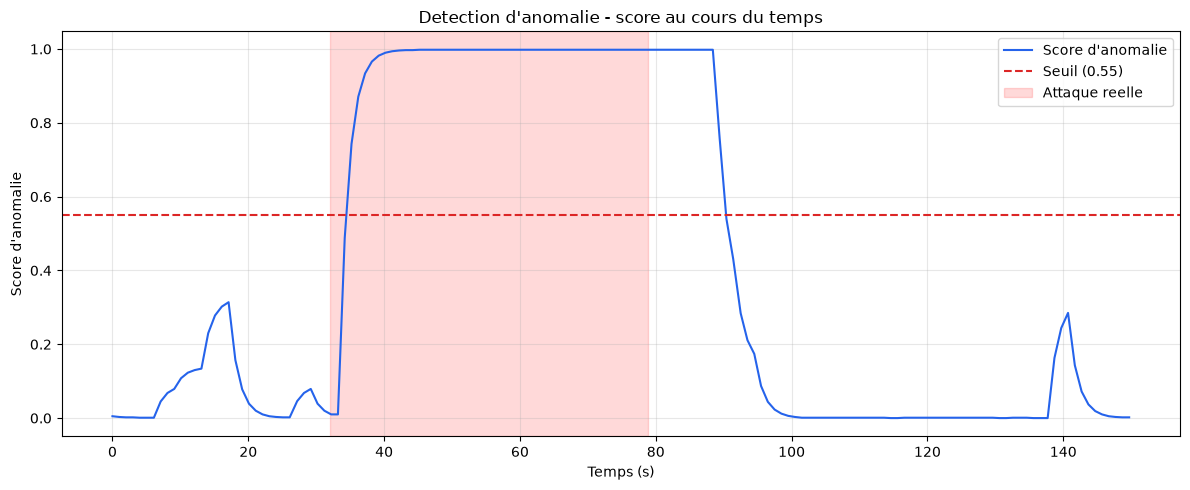

In [4]:
t0 = df["t"].iloc[0]
temps = df["t"] - t0

plt.figure(figsize=(12, 5))
plt.plot(temps, df["score"], label="Score d'anomalie", color="#2563eb", linewidth=1.5)
plt.axhline(THRESHOLD, color="#dc2626", linestyle="--", label=f"Seuil ({THRESHOLD})")
plt.axvspan(ATTACK_START - t0, ATTACK_END - t0, alpha=0.15, color="red", label="Attaque reelle")
plt.xlabel("Temps (s)")
plt.ylabel("Score d'anomalie")
plt.title("Detection d'anomalie - score au cours du temps")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Lecture du graphique

La courbe met en évidence les **trois phases** du scénario :
1. **Avant l'attaque** : le score reste proche de 0 (bruit normal < 0,05), bien en dessous du seuil.
2. **Pendant l'attaque** (zone rouge) : le score grimpe brutalement jusqu'à ~0,99 et dépasse nettement le seuil de 0,55 — l'alerte est confirmée.
3. **Après l'attaque** : le score redescend vers 0, traduisant le retour du service à la normale.

Cette séparation nette entre le régime normal et le régime sous attaque explique le bon AUC-ROC obtenu.

## Interprétation et limites

- **Recall élevé** : le détecteur capte la quasi-totalité de l'attaque.
- **Faux positifs** : juste après l'attaque, le temps que le score redescende sous le seuil.
- **Faux négatifs** : les premières secondes, le temps que la persistance (3 points) se confirme — c'est le délai de détection.
- **Pistes** : ajuster le seuil/la persistance selon le compromis sensibilité/fausses alertes ; ajouter CPU/RAM (cAdvisor).
